# Acquisition Function Output Analysis (Random IV): Multiscale and Single Scale

Load the saved active-learning results from `iv_acqfn_script.py` and compare random acquisition with the distance
acquisition function ($\beta=1$), for multiscale (`ms`, scales 4–32) and single scale (`ss`, WS = 32).
Mirrors `notebooks/STM/acfn_output_analysis1.ipynb`.

Differences from the STM data (see `obs.md`):
- 2001 measured points; IV positions shifted by (−12, +7) px; border patches padded (image 0, mask 0).
- The mask channel is used for both `ss` and `ms`.
- `reduced_coords` columns are **(row, col, scale)** and are in point order (row `i` is point `i`).
- Errors are L1 in the original current units (smoothed IV curves).

In [ ]:
%matplotlib inline

import re
import sys
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt

cwd = Path.cwd()
iv_dir = cwd / "notebooks" / "Random_IV" if (cwd / "notebooks" / "Random_IV").exists() else cwd
results_dir = iv_dir / "data" / "active_learning_results"

# Run settings (must match the file names written by iv_acqfn_script.py)
model_type = "im2spec"
error_type = "L1"
WS = 32
latent_dim = 5
acquisition_iterations = 50
num_new_points = 5
norm_type = "normgauss"
mask_suffix = "_mask"          # the mask channel is on for both ss and ms in the IV runs
offset = (-12, 7)


def build_result_file(acquisition, scale_type):
    return results_dir / (
        f"al_{model_type}_{error_type}_WS{WS}_latent{latent_dim}_appendpad_"
        f"{acquisition_iterations}iters_{num_new_points}pts_"
        f"{acquisition}acq_{scale_type}_{norm_type}{mask_suffix}_off{offset[0]}_{offset[1]}.h5"
    )


def load_h5_ragged(filename):
    data_dict = {}
    with h5py.File(filename, "r") as f:
        for key in f.keys():
            group = f[key]
            data_dict[key] = [group[str(i)][()] for i in range(len(group))]
    return data_dict


def infer_num_new_points(output_dict, output_file, fallback=5):
    match = re.search(r"_(\d+)pts_", Path(output_file).name)
    if match:
        return int(match.group(1))
    train_indices = output_dict.get("train_indices", [])
    if len(train_indices) > 1:
        return int(len(train_indices[1]) - len(train_indices[0]))
    return fallback


def plot_reduced_errors_and_scales(errors, coords_reduced, aq_indices=None, title_prefix=""):
    """Reduced (minimum over scales) predicted error and the best scale, on image (col, row) axes."""
    rows, cols, scales = coords_reduced[:, 0], coords_reduced[:, 1], coords_reduced[:, 2]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sc0 = axes[0].scatter(cols, rows, c=errors, s=12)
    axes[0].set_title(f"{title_prefix}Reduced minimum error, mean = {np.mean(errors):.3g}")
    plt.colorbar(sc0, ax=axes[0], label="Minimum predicted error")

    uniq = np.unique(scales)
    sc1 = axes[1].scatter(cols, rows, c=scales, s=12, cmap="viridis", vmin=uniq.min(), vmax=uniq.max())
    axes[1].set_title(f"{title_prefix}Best scale at each point")
    cb = plt.colorbar(sc1, ax=axes[1], label="Best scale (px)")
    cb.set_ticks(uniq)

    if aq_indices is not None and len(aq_indices) > 0:
        aq_indices = np.asarray(aq_indices, dtype=int)
        axes[0].scatter(cols[aq_indices], rows[aq_indices], marker="x", s=120, linewidths=2, c="r",
                        label="Acquisition points")
        axes[0].legend(loc="upper right")

    for ax in axes:
        ax.set_xlabel("col (px)")
        ax.set_ylabel("row (px)")
        ax.set_xlim(0, 127)
        ax.set_ylim(0, 127)
        ax.set_aspect("equal")
    plt.tight_layout()
    plt.show()


default_scale_type = "ms"
output_file = build_result_file("distance", default_scale_type)
print(output_file.name, output_file.exists())

al_im2spec_L1_WS32_latent5_appendpad_50iters_5pts_distanceacq_ms_normgauss_mask_off-12_7.h5 True


In [ ]:
output_dict = load_h5_ragged(output_file)
{key: len(value) for key, value in output_dict.items()}

{'im2spec_test_mismatches': 50,
 'point_coords': 1,
 'pred_error_test': 50,
 'predicted_errors_all': 50,
 'recorded_coords': 1,
 'reduced_coords': 50,
 'reduced_errors': 50,
 'reduced_errors_im2spec': 50,
 'scales': 1,
 'test_indices': 50,
 'train_indices': 50}

In [ ]:
# Sanity checks on the saved layout
point_coords = output_dict["point_coords"][0]          # (2001, 2) (row, col) after the offset
scales_saved = output_dict["scales"][0]
print("scales:", scales_saved.tolist())
print("reduced_coords are in point order:",
      all(np.array_equal(rc[:, :2].astype(int), point_coords) for rc in output_dict["reduced_coords"]))
print("offset applied:", np.unique(point_coords - output_dict["recorded_coords"][0], axis=0).tolist())

scales: [4, 8, 12, 16, 20, 24, 28, 32]
reduced_coords are in point order: True
offset applied: [[-12, 7]]


## Acquired points (distance acquisition, multiscale)

(445,)
Acquired points: 245


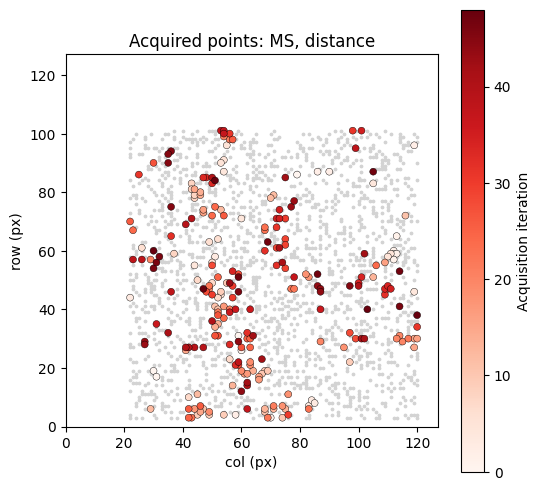

In [ ]:
train_indices = output_dict["train_indices"]
# acquired points, in acquisition order
acquired_indices = np.asarray([i for i in train_indices[-1] if i not in set(train_indices[0])], dtype=int)
acq_coords = point_coords[acquired_indices]

print(train_indices[-1].shape)
print(f"Acquired points: {len(acquired_indices)}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(point_coords[:, 1], point_coords[:, 0], s=3, c="lightgray", label="all points")
sc = ax.scatter(acq_coords[:, 1], acq_coords[:, 0], c=np.arange(len(acq_coords)) // num_new_points,
                cmap="Reds", marker="o", s=25, edgecolors="k", linewidths=0.3)
plt.colorbar(sc, ax=ax, label="Acquisition iteration")
ax.set_xlim(0, 127); ax.set_ylim(0, 127); ax.set_aspect("equal")
ax.set_xlabel("col (px)"); ax.set_ylabel("row (px)")
ax.set_title(f"Acquired points: {default_scale_type.upper()}, distance")
plt.show()

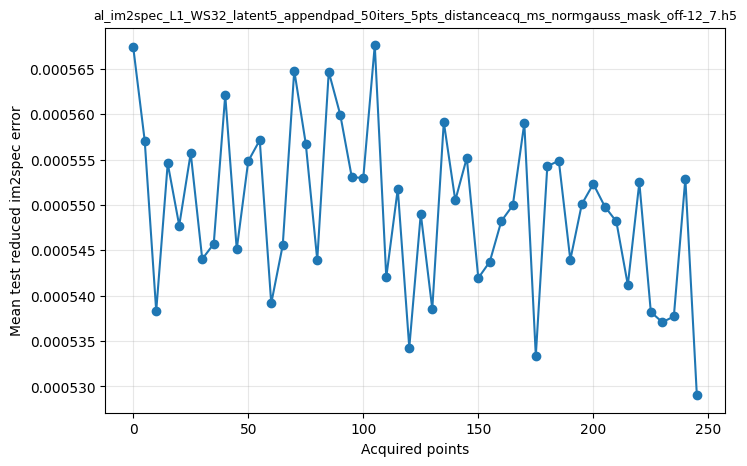

In [ ]:
train_indices_arr = output_dict["train_indices"]
test_indices_arr = [indices.astype(int) for indices in output_dict["test_indices"]]
reduced_errors_arr = np.array(output_dict["reduced_errors_im2spec"])

num_saved_iterations = len(reduced_errors_arr)
points_per_iteration = infer_num_new_points(output_dict, output_file)
test_reduced_errors = [reduced_errors_arr[i][test_indices_arr[i]] for i in range(num_saved_iterations)]
mean_test_reduced_errors = [np.mean(errors) for errors in test_reduced_errors]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(np.arange(num_saved_iterations) * points_per_iteration, mean_test_reduced_errors, marker="o")
ax.set_xlabel("Acquired points")
ax.set_ylabel("Mean test reduced im2spec error")
ax.set_title(Path(output_file).name, fontsize=9)
ax.grid(True, alpha=0.3)
plt.show()

Plotting iteration -2 from al_im2spec_L1_WS32_latent5_appendpad_50iters_5pts_distanceacq_ms_normgauss_mask_off-12_7.h5


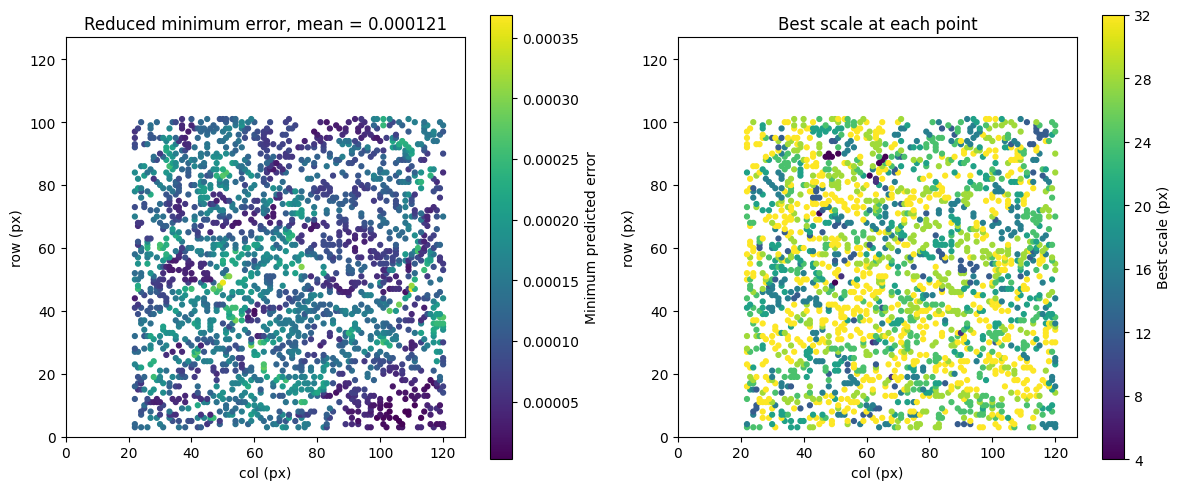

In [ ]:
plot_iteration = -2
error_key = "reduced_errors"

reduced_errors_to_plot = np.asarray(output_dict[error_key][plot_iteration])
reduced_coords_to_plot = np.asarray(output_dict["reduced_coords"][plot_iteration])

print(f"Plotting iteration {plot_iteration} from {Path(output_file).name}")
plot_reduced_errors_and_scales(reduced_errors_to_plot, reduced_coords_to_plot)

## Compare random and distance acquisition by scale type

Multiscale (`ms`) and single-scale (`ss`) results are displayed in separate figures. Random acquisition is blue;
distance acquisition ($\beta=1$) is orange. The grey dashed line is the **mean-spectrum baseline**: predict the mean
training spectrum for every test point (computed from the data at each iteration's train/test split).

In [ ]:
# Mean-spectrum baseline needs the spectra: same loading/smoothing as iv_acqfn_script.py
if str(iv_dir) not in sys.path:
    sys.path.insert(0, str(iv_dir))
from helper_fns import load_random_iv, smooth_spectra

data = load_random_iv(iv_dir / "content" / "V3_IV_map_1d2um_0002.h5", iv_dir / "content" / "V3_IV_spec_1d2um_0003.h5")
spectra_all = smooth_spectra(data["iv"]).astype(np.float64)
assert np.array_equal(data["coords"], output_dict["recorded_coords"][0]), "spectra order differs from the saved run"
spectra_all.shape


def mean_spectrum_baseline(result_dict):
    """Mean L1 on the test points when every test point is predicted by the mean training spectrum."""
    out = []
    for tr, te in zip(result_dict["train_indices"], result_dict["test_indices"]):
        mean_spec = spectra_all[np.asarray(tr, dtype=int)].mean(axis=0)
        out.append(np.mean(np.abs(spectra_all[np.asarray(te, dtype=int)] - mean_spec)))
    return np.asarray(out)

In [ ]:
def calculate_mean_test_reduced_im2spec_error(output_dict):
    reduced_errors = output_dict["reduced_errors_im2spec"]
    test_indices = output_dict["test_indices"]
    if len(reduced_errors) != len(test_indices):
        raise ValueError("reduced_errors_im2spec and test_indices have different iteration counts")
    return np.asarray([
        np.mean(np.asarray(errors)[np.asarray(indices, dtype=int)])
        for errors, indices in zip(reduced_errors, test_indices)
    ])


scale_labels = {"ms": "Multiscale (MS)", "ss": "Single scale (SS)"}
acquisition_colors = {"random": "tab:blue", "distance": "tab:orange"}
acquisition_labels = {"random": "Random", "distance": "Acquisition function ($\\beta=1$)"}

comparison_results = {}
for scale_type in ("ms", "ss"):
    comparison_results[scale_type] = {}
    for acquisition in ("random", "distance"):
        result_file = build_result_file(acquisition, scale_type)
        if not result_file.exists():
            raise FileNotFoundError(result_file)
        result_dict = load_h5_ragged(result_file)
        mean_errors = calculate_mean_test_reduced_im2spec_error(result_dict)
        points_per_iteration = infer_num_new_points(result_dict, result_file)
        comparison_results[scale_type][acquisition] = {
            "output_file": result_file,
            "output_dict": result_dict,
            "acquired_points": np.arange(len(mean_errors)) * points_per_iteration,
            "mean_test_reduced_im2spec_error": mean_errors,
            "baseline": mean_spectrum_baseline(result_dict),
        }

for scale_type, res in comparison_results.items():
    for acquisition, r in res.items():
        e = r["mean_test_reduced_im2spec_error"]
        print(f"{scale_type} {acquisition:8s}: first {e[0]:.3e}, last {e[-1]:.3e}, min {e.min():.3e}; "
              f"baseline first {r['baseline'][0]:.3e}, last {r['baseline'][-1]:.3e}")

ms random  : first 5.674e-04, last 5.411e-04, min 5.284e-04; baseline first 5.220e-04, last 5.226e-04
ms distance: first 5.674e-04, last 5.290e-04, min 5.290e-04; baseline first 5.220e-04, last 5.233e-04
ss random  : first 5.602e-04, last 5.515e-04, min 5.358e-04; baseline first 5.220e-04, last 5.226e-04
ss distance: first 5.602e-04, last 5.206e-04, min 5.206e-04; baseline first 5.220e-04, last 5.227e-04


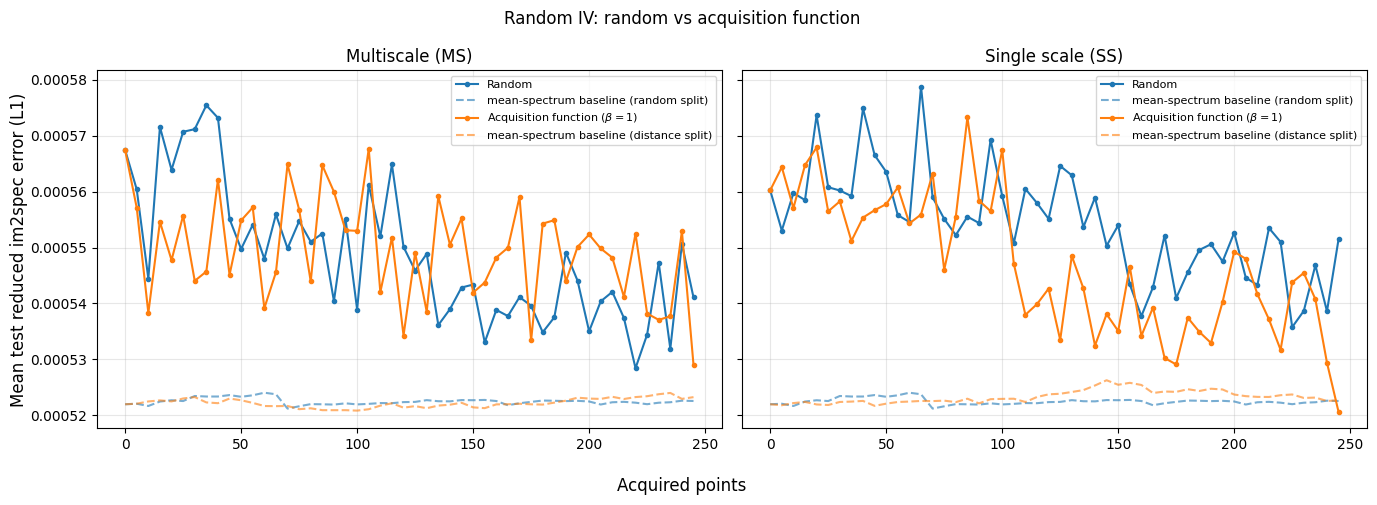

In [ ]:
# Mean test-error series: one panel for MS and one for SS (same y-axis).
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for ax, scale_type in zip(axes, ("ms", "ss")):
    for acquisition in ("random", "distance"):
        r = comparison_results[scale_type][acquisition]
        ax.plot(r["acquired_points"], r["mean_test_reduced_im2spec_error"], color=acquisition_colors[acquisition],
                marker="o", markersize=3, label=acquisition_labels[acquisition])
        ax.plot(r["acquired_points"], r["baseline"], color=acquisition_colors[acquisition], ls="--", alpha=0.6,
                label=f"mean-spectrum baseline ({acquisition} split)")
    ax.set_title(scale_labels[scale_type])
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
fig.supxlabel("Acquired points")
fig.supylabel(f"Mean test reduced im2spec error ({error_type})")
fig.suptitle("Random IV: random vs acquisition function")
fig.tight_layout()
plt.show()

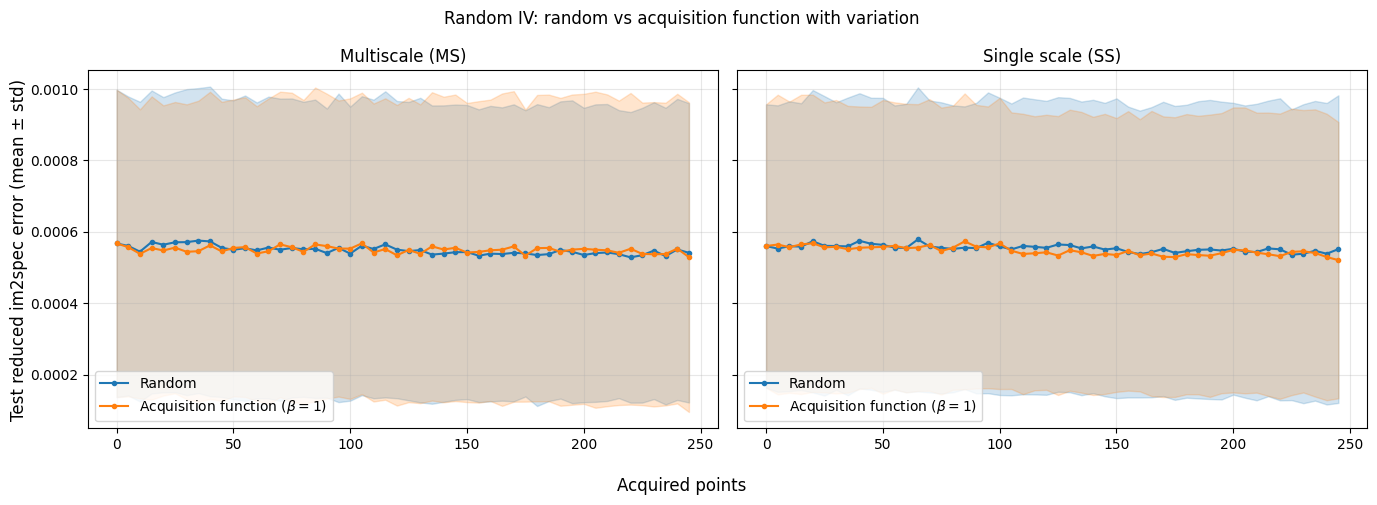

In [ ]:
# Mean ± standard deviation over the test points
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for ax, scale_type in zip(axes, ("ms", "ss")):
    for acquisition in ("random", "distance"):
        r = comparison_results[scale_type][acquisition]
        rd = r["output_dict"]
        test_errors = [np.asarray(e)[np.asarray(i, dtype=int)]
                       for e, i in zip(rd["reduced_errors_im2spec"], rd["test_indices"])]
        std_errors = np.asarray([np.std(e) for e in test_errors])
        mean_errors = r["mean_test_reduced_im2spec_error"]
        x = r["acquired_points"]
        ax.plot(x, mean_errors, color=acquisition_colors[acquisition], marker="o", markersize=3,
                label=acquisition_labels[acquisition])
        ax.fill_between(x, mean_errors - std_errors, mean_errors + std_errors,
                        color=acquisition_colors[acquisition], alpha=0.2)
    ax.set_title(scale_labels[scale_type])
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.supxlabel("Acquired points")
fig.supylabel("Test reduced im2spec error (mean ± std)")
fig.suptitle("Random IV: random vs acquisition function with variation")
fig.tight_layout()
plt.show()

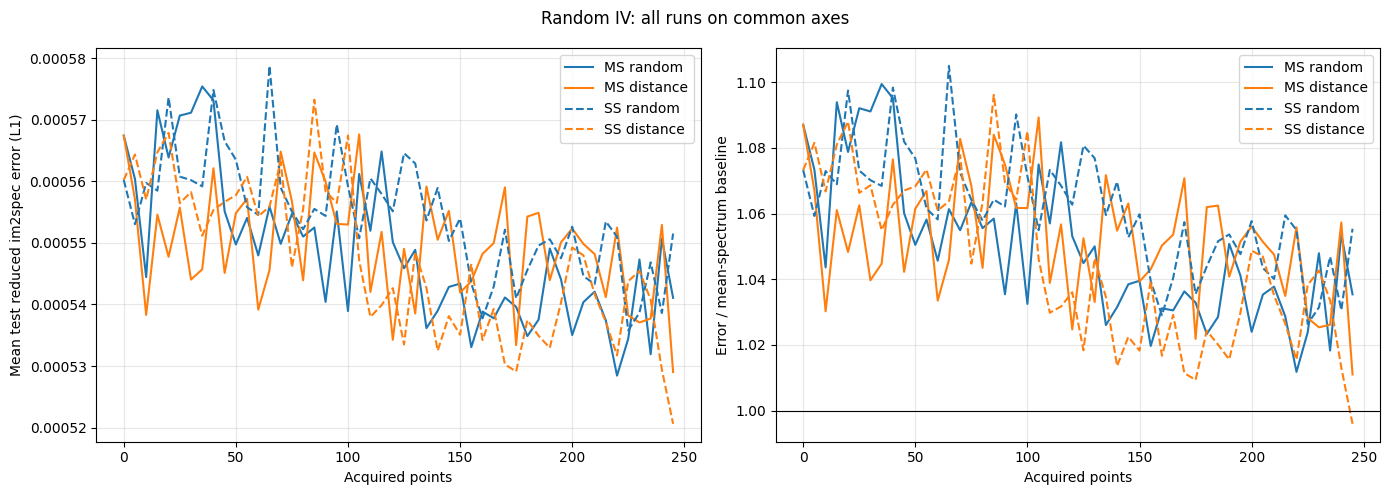

In [ ]:
# All four runs on one axis (MS solid, SS dashed), relative to the mean-spectrum baseline
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for scale_type, ls in (("ms", "-"), ("ss", "--")):
    for acquisition in ("random", "distance"):
        r = comparison_results[scale_type][acquisition]
        lab = f"{scale_type.upper()} {acquisition}"
        axes[0].plot(r["acquired_points"], r["mean_test_reduced_im2spec_error"], ls=ls,
                     color=acquisition_colors[acquisition], label=lab)
        axes[1].plot(r["acquired_points"], r["mean_test_reduced_im2spec_error"] / r["baseline"], ls=ls,
                     color=acquisition_colors[acquisition], label=lab)
axes[0].set_ylabel(f"Mean test reduced im2spec error ({error_type})")
axes[1].set_ylabel("Error / mean-spectrum baseline")
axes[1].axhline(1, color="k", lw=0.8)
for ax in axes:
    ax.set_xlabel("Acquired points")
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.suptitle("Random IV: all runs on common axes")
fig.tight_layout()
plt.show()

## Error-model skill

The distance acquisition can only help if the error model ranks points correctly. Below: Spearman correlation between
the predicted error and the true im2spec error on the test rows (all scales for `ms`), per iteration.

ms random  : Spearman first +0.008, last -0.014, mean +0.009
ms distance: Spearman first +0.008, last +0.029, mean +0.015
ss random  : Spearman first +0.061, last +0.032, mean +0.050
ss distance: Spearman first +0.061, last +0.073, mean +0.050


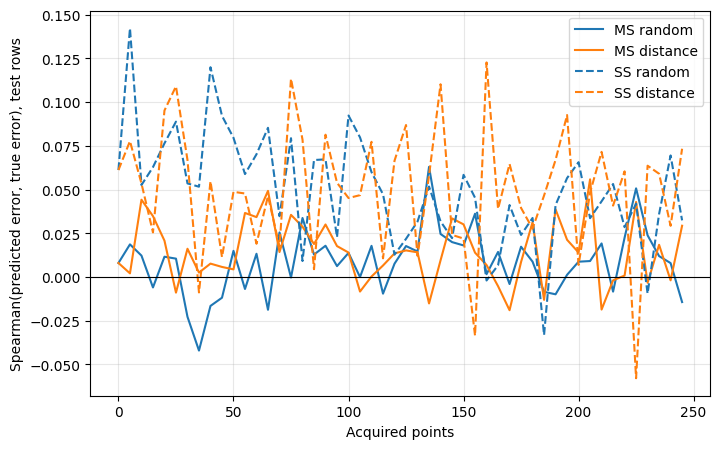

In [ ]:
from scipy.stats import spearmanr

fig, ax = plt.subplots(figsize=(8, 5))
for scale_type, ls in (("ms", "-"), ("ss", "--")):
    for acquisition in ("random", "distance"):
        rd = comparison_results[scale_type][acquisition]["output_dict"]
        rho = [spearmanr(p, t)[0] for p, t in zip(rd["pred_error_test"], rd["im2spec_test_mismatches"])]
        ax.plot(comparison_results[scale_type][acquisition]["acquired_points"], rho, ls=ls,
                color=acquisition_colors[acquisition], label=f"{scale_type.upper()} {acquisition}")
        print(f"{scale_type} {acquisition:8s}: Spearman first {rho[0]:+.3f}, last {rho[-1]:+.3f}, mean {np.mean(rho):+.3f}")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Acquired points")
ax.set_ylabel("Spearman(predicted error, true error), test rows")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

## Multiscale: true test error per scale

For the `ms` runs, the test rows are stored in blocks of one scale each, so the true im2spec error can be split by
scale. "reduced" is the error at the scale the error model picked; "oracle" is the minimum true error over scales.

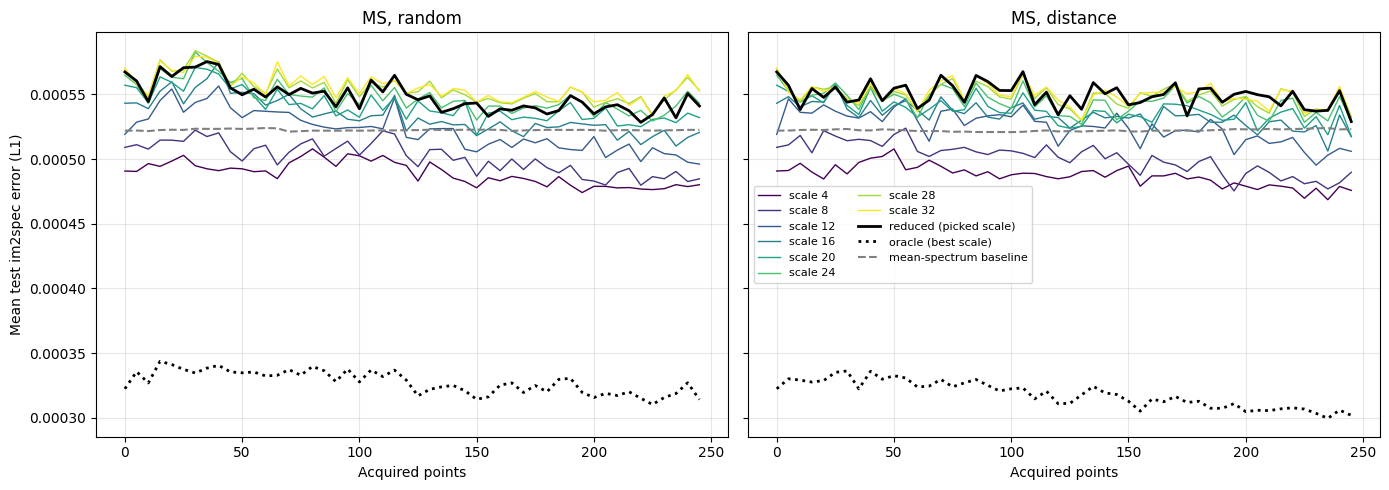

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, acquisition in zip(axes, ("random", "distance")):
    r = comparison_results["ms"][acquisition]
    rd = r["output_dict"]
    scales = rd["scales"][0]
    S = len(scales)
    per_scale = np.array([np.asarray(t).reshape(S, -1).mean(axis=1) for t in rd["im2spec_test_mismatches"]])
    oracle = np.array([np.asarray(t).reshape(S, -1).min(axis=0).mean() for t in rd["im2spec_test_mismatches"]])
    colors = plt.cm.viridis(np.linspace(0, 1, S))
    for k in range(S):
        ax.plot(r["acquired_points"], per_scale[:, k], color=colors[k], lw=1, label=f"scale {scales[k]}")
    ax.plot(r["acquired_points"], r["mean_test_reduced_im2spec_error"], "k-", lw=2, label="reduced (picked scale)")
    ax.plot(r["acquired_points"], oracle, "k:", lw=2, label="oracle (best scale)")
    ax.plot(r["acquired_points"], r["baseline"], color="gray", ls="--", label="mean-spectrum baseline")
    ax.set_title(f"MS, {acquisition}")
    ax.set_xlabel("Acquired points")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel(f"Mean test im2spec error ({error_type})")
axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()